# Edge End-to-End Benchmark: Raw Audio to Decision on the ESP32-S3

The board receives raw 3.0-second audio clips, computes the PCEN Mel spectrogram itself, runs the INT8 model, and returns its decision with timings. The results are compared with the laptop pipeline (librosa features and the same INT8 model file) on the same clips.

Test clips come from the test subset of the recording split, the same subset the training experiment evaluates on. No recording in it was used for training or validation.


## 1. Imports and Configuration


In [1]:
import hashlib
import json
import struct
import time
import warnings
from pathlib import Path

import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import serial
import soundfile as sf
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["figure.dpi"] = 150

SEED = 42

def find_project_root():
    p = Path.cwd().resolve()
    while p != p.parent:
        if (p / "data").exists() and (p / "AGENTS.md").exists():
            return p
        p = p.parent
    return Path.cwd().resolve().parent.parent

PROJECT_ROOT = find_project_root()
EXPERIMENT_DIR = Path.cwd().resolve()
OUTPUTS_DIR = EXPERIMENT_DIR / "outputs"
FIGURES_DIR = OUTPUTS_DIR / "figures"
for d in [OUTPUTS_DIR, FIGURES_DIR]:
    d.mkdir(parents=True, exist_ok=True)

DATA_DIR = PROJECT_ROOT / "data"
AUDIO_3S_DIR = DATA_DIR / "preprocessed" / "3-seconds" / "audios"
FEATURES_3S_DIR = DATA_DIR / "features" / "3-seconds" / "pcen-melSpectrogram"
META_3S_PATH = FEATURES_3S_DIR / "features_metadata.csv"
if not META_3S_PATH.exists():
    META_3S_PATH = DATA_DIR / "features" / "3-seconds" / "features_metadata.csv"

# Firmware project and the exact INT8 model file that is flashed on the board
PLATFORMIO_PROJECT = Path.home() / "Documents" / "PlatformIO" / "Projects" / "ph-eagle-edge-device"
BOARD_MODEL_PATH = PLATFORMIO_PROJECT / "models" / "crnn-gru-3s-edge-cost-sensitive-int8-static-2026-10-12.tflite"
FIRMWARE_CONSTANTS_PATH = PLATFORMIO_PROJECT / "include" / "feature_constants.h"

# Feature extraction parameters (same as the feature-extraction experiment)
SR, N_FFT, HOP, N_MELS, N_FRAMES, N_SAMPLES = 22050, 2048, 512, 128, 130, 66150
PCEN_GAIN, PCEN_BIAS, PCEN_POWER, PCEN_TIME_CONSTANT, PCEN_EPS = 0.98, 2.0, 0.5, 0.4, 1e-6

# Serial link to the board
SERIAL_PORT = "/dev/ttyACM0"
BAUD_RATE = 921600

# Clips per group (Eagle, Ambient, Hard negative): 20 for a quick check, None for the whole test subset (the reported run)
CLIPS_PER_GROUP = None
FEATURE_MATCH_CLIPS_PER_GROUP = 3
GROUPS = ["Eagle", "Ambient", "Hard negative"]

print(f"Project root:      {PROJECT_ROOT}")
print(f"Audio clips:       {AUDIO_3S_DIR}")
print(f"Board model file:  {BOARD_MODEL_PATH} (exists: {BOARD_MODEL_PATH.exists()})")
print(f"Serial interface:  {SERIAL_PORT} @ {BAUD_RATE} baud")
print(f"Clips per group:   {CLIPS_PER_GROUP if CLIPS_PER_GROUP is not None else 'all (whole test subset)'}")


I0000 00:00:1791783913.327926   13317 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791783913.361191   13317 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791783914.236580   13317 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Project root:      /home/fumei/Documents/MachineLearning/EagleSoundClassification
Audio clips:       /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/preprocessed/3-seconds/audios
Board model file:  /home/fumei/Documents/PlatformIO/Projects/ph-eagle-edge-device/models/crnn-gru-3s-edge-cost-sensitive-int8-static-2026-10-12.tflite (exists: True)
Serial interface:  /dev/ttyACM0 @ 921600 baud
Clips per group:   all (whole test subset)


## 2. Select Test Clips from the Test Subset of the Recording Split

In [2]:
# Same recording-level split function and seed as the CRNN-GRU training notebook
def create_recording_split(df_clean, train_ratio=0.70, val_ratio=0.15, random_state=SEED):
    """
    Recording-level split: every source recording is assigned to exactly one subset.
    1. Recordings are grouped into strata: eagle recordings by site (the two main sites, and the
       smaller sites together) and hard-negative recordings by species.
    2. Within each stratum the recordings are shuffled and divided into Train, Val, and Test.
    3. All clips of a recording follow it. Augmented clips are kept only for Train recordings.
    Returns the train, val, and test indices and a table with the subset of every recording.
    """
    df_orig = df_clean[~df_clean["is_augmented"]]
    recordings = df_orig.groupby("source_audio").agg(
        dataset_source=("dataset_source", "first"),
        site=("site", "first"),
        species=("species", "first"),
        clips=("label", "size"),
        eagle_clips=("label", "sum"),
    ).reset_index()

    main_sites = {"Davao del Sur", "Cotabato"}
    is_eagle_recording = recordings["dataset_source"] == "eagle-audios"
    recordings["stratum"] = np.where(
        is_eagle_recording,
        "eagle | " + recordings["site"].where(recordings["site"].isin(main_sites), "other sites"),
        "hard negative | " + recordings["species"],
    )

    rng = np.random.default_rng(random_state)
    test_ratio = 1.0 - train_ratio - val_ratio
    assignment = {}
    for _, group in recordings.groupby("stratum", sort=True):
        names = rng.permutation(np.sort(group["source_audio"].values))
        n = len(names)
        n_test = max(1, int(round(n * test_ratio))) if n >= 3 else 0
        n_val = max(1, int(round(n * val_ratio))) if n >= 3 else 0
        for position, name in enumerate(names):
            assignment[name] = "test" if position < n_test else ("val" if position < n_test + n_val else "train")

    recordings["split"] = recordings["source_audio"].map(assignment)
    clip_split = df_clean["source_audio"].map(assignment).values
    is_aug = df_clean["is_augmented"].values

    train_idx = np.where(clip_split == "train")[0]
    val_idx = np.where((clip_split == "val") & ~is_aug)[0]
    test_idx = np.where((clip_split == "test") & ~is_aug)[0]
    return train_idx, val_idx, test_idx, recordings


df_meta = pd.read_csv(META_3S_PATH)
df_clean = df_meta[~df_meta["has_ambiguous"]].reset_index(drop=True)
train_idx, val_idx, test_idx, df_recordings = create_recording_split(df_clean)

# The test subset must share no recording with the training or validation subset
sources = df_clean["source_audio"].values
seen_sources = set(sources[train_idx]) | set(sources[val_idx])
assert not (set(sources[test_idx]) & seen_sources), "A test recording was also used for training or validation"
assert not df_clean["is_augmented"].values[test_idx].any(), "Augmented clips found in the test subset"

df_pool = df_clean.iloc[test_idx].copy()
df_pool["group"] = np.where(
    df_pool["label"] == 1, "Eagle",
    np.where(df_pool["dataset_source"] == "hard-negatives", "Hard negative", "Ambient")
)
df_pool["audio_file"] = df_pool["feature_file"].str.replace(".npy", ".wav", regex=False)

# Put the clips of each group in a fixed random order; a quick check uses the first CLIPS_PER_GROUP of each
rng_pick = np.random.default_rng(SEED)
picked = []
for group in GROUPS:
    g = df_pool[df_pool["group"] == group]
    g = g.iloc[rng_pick.permutation(len(g))].copy()
    g["rank_in_group"] = np.arange(len(g))
    picked.append(g)
df_clips = pd.concat(picked, ignore_index=True)
df_clips["in_quick_subset"] = df_clips["rank_in_group"] < 20

clip_cols = ["group", "rank_in_group", "in_quick_subset", "audio_file", "feature_file", "label", "species", "site", "source_audio"]
clips_csv_path = OUTPUTS_DIR / "test-clips.csv"
df_clips[clip_cols].to_csv(clips_csv_path, index=False)

df_eval = df_clips if CLIPS_PER_GROUP is None else df_clips[df_clips["rank_in_group"] < CLIPS_PER_GROUP]
df_eval = df_eval.reset_index(drop=True)
df_eval["clip_idx"] = np.arange(len(df_eval))

print(f"Split sizes: train {len(train_idx):,}, val {len(val_idx):,}, test {len(test_idx):,} clips")
print(f"Test subset clips available: {len(df_pool):,}")
print(df_pool.groupby("group").agg(clips=("label", "size"), recordings=("source_audio", "nunique")).to_string())
print(f"\nSaved the full clip list ({len(df_clips)} clips) to: {clips_csv_path}")
print(f"Clips in this run: {len(df_eval)}")
display(df_eval[["clip_idx", "group", "audio_file", "species", "site"]].head(10))


Split sizes: train 10,684, val 1,794, test 1,009 clips
Test subset clips available: 1,009
               clips  recordings
group                           
Ambient          236           6
Eagle            450           8
Hard negative    323          77

Saved the full clip list (1009 clips) to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/edge-end-to-end-benchmark/outputs/test-clips.csv
Clips in this run: 1009


,clip_idx,group,audio_file,species,site
0,0,Eagle,converted_18677_00219.0_00222.0.wav,Philippine Eagle,Cotabato
1,1,Eagle,converted_18655_00141.0_00144.0.wav,Philippine Eagle,Cotabato
2,2,Eagle,converted_18655_00127.5_00130.5.wav,Philippine Eagle,Cotabato
3,3,Eagle,converted_18655_00162.0_00165.0.wav,Philippine Eagle,Cotabato
4,4,Eagle,converted_18677_00028.5_00031.5.wav,Philippine Eagle,Cotabato
5,5,Eagle,converted_18677_00225.0_00228.0.wav,Philippine Eagle,Cotabato
6,6,Eagle,converted_18677_00303.0_00306.0.wav,Philippine Eagle,Cotabato
7,7,Eagle,converted_18655_00108.0_00111.0.wav,Philippine Eagle,Cotabato
8,8,Eagle,converted_18532_00265.5_00268.5.wav,Philippine Eagle,Davao del Sur
9,9,Eagle,converted_18655_00075.0_00078.0.wav,Philippine Eagle,Cotabato


## 3. Export Firmware Feature Constants


In [3]:
def build_feature_constants_header():
    """C++ header with the window, Mel filterbank and PCEN constants used by the ESP32 firmware."""
    assert PCEN_POWER == 0.5, "the firmware implements the PCEN power as a square root"
    hann = librosa.filters.get_window("hann", N_FFT, fftbins=True).astype(np.float32)
    mel = librosa.filters.mel(sr=SR, n_fft=N_FFT, n_mels=N_MELS, fmin=0, fmax=SR // 2).astype(np.float32)
    t_frames = PCEN_TIME_CONSTANT * SR / HOP
    b = (np.sqrt(1 + 4 * t_frames**2) - 1) / (2 * t_frames**2)
    starts, lengths, offsets, weights = [], [], [], []
    for band in mel:
        nz = np.flatnonzero(band)
        assert len(nz) > 0 and np.all(np.diff(nz) == 1), "each Mel band must be one contiguous run of bins"
        starts.append(int(nz[0])); lengths.append(len(nz)); offsets.append(len(weights)); weights.extend(band[nz].tolist())
    def f(v):
        text = f"{np.float32(v):.9g}"
        return (text if ("." in text or "e" in text) else text + ".0") + "f"
    rows = lambda vals, fmt, per: ",\n".join("    " + ", ".join(fmt(v) for v in vals[i:i + per]) for i in range(0, len(vals), per))
    return "\n".join([
        "#pragma once",
        "#include <cstdint>",
        "",
        "// Generated by experiments/edge-end-to-end-benchmark/edge-end-to-end-benchmark.ipynb (section 3).",
        "// Hann window, sparse Mel filterbank and PCEN constants, taken from librosa so the board matches the laptop.",
        "namespace feature_constants {",
        "",
        f"constexpr int kSampleRate = {SR};",
        f"constexpr int kNumSamples = {N_SAMPLES};",
        f"constexpr int kFftSize = {N_FFT};",
        f"constexpr int kHopLength = {HOP};",
        f"constexpr int kNumBins = {N_FFT // 2 + 1};",
        f"constexpr int kNumMel = {N_MELS};",
        f"constexpr int kNumFrames = {N_FRAMES};",
        f"constexpr int kNumMelWeights = {len(weights)};",
        "",
        f"constexpr float kMelScale = {f(2.0**31)};   // magnitude scaling applied before PCEN",
        f"constexpr float kPcenB = {f(b)};          // smoothing coefficient for a {PCEN_TIME_CONSTANT} s time constant",
        f"constexpr float kPcenZi = {f(1.0 - b)};         // initial filter state",
        f"constexpr float kPcenGain = {f(PCEN_GAIN)};",
        f"constexpr float kPcenBias = {f(PCEN_BIAS)};",
        f"constexpr float kPcenEps = {f(PCEN_EPS)};",
        "",
        f"alignas(16) const float kHann[{N_FFT}] = {{", rows(hann.tolist(), f, 6), "};",
        "",
        f"const uint16_t kMelStart[{N_MELS}] = {{", rows(starts, str, 16), "};",
        "",
        f"const uint16_t kMelLength[{N_MELS}] = {{", rows(lengths, str, 16), "};",
        "",
        f"const uint16_t kMelOffset[{N_MELS}] = {{", rows(offsets, str, 16), "};",
        "",
        f"const float kMelWeights[{len(weights)}] = {{", rows(weights, f, 6), "};",
        "",
        "}  // namespace feature_constants",
        ""])


# Write the header next to this experiment and check it against the copy compiled into the firmware
header_text = build_feature_constants_header()
header_out_path = OUTPUTS_DIR / "feature_constants.h"
header_out_path.write_text(header_text)
print(f"Saved feature constants header to: {header_out_path}")

if FIRMWARE_CONSTANTS_PATH.exists():
    same = FIRMWARE_CONSTANTS_PATH.read_text() == header_text
    print(f"Firmware copy at {FIRMWARE_CONSTANTS_PATH}: {'identical' if same else 'DIFFERENT - copy the new header into the firmware, then rebuild and flash'}")
else:
    print(f"No firmware copy found at {FIRMWARE_CONSTANTS_PATH}")


Saved feature constants header to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/edge-end-to-end-benchmark/outputs/feature_constants.h
Firmware copy at /home/fumei/Documents/PlatformIO/Projects/ph-eagle-edge-device/include/feature_constants.h: identical


## 4. Compute Laptop Reference Features and Predictions


In [4]:
# Laptop pipeline: librosa PCEN Mel spectrogram, then the same INT8 model file that is on the board
interpreter = tf.lite.Interpreter(model_path=str(BOARD_MODEL_PATH))
interpreter.allocate_tensors()
input_details = interpreter.get_input_details()[0]
output_details = interpreter.get_output_details()[0]
input_scale, input_zero_point = input_details["quantization"]
output_scale, output_zero_point = output_details["quantization"]

def load_pcm(audio_file):
    """Read a clip as 16-bit PCM, exactly as it is sent to the board."""
    pcm, sr = sf.read(AUDIO_3S_DIR / audio_file, dtype="int16")
    assert sr == SR and pcm.ndim == 1 and len(pcm) == N_SAMPLES, f"unexpected format: {audio_file}"
    return pcm

def laptop_features_int8(audio_file):
    """PCEN Mel spectrogram with librosa, quantized with the model's input scale and zero point."""
    y, _ = sf.read(AUDIO_3S_DIR / audio_file)
    mel = librosa.feature.melspectrogram(y=y, sr=SR, n_fft=N_FFT, hop_length=HOP, n_mels=N_MELS, fmin=0, fmax=SR // 2, power=1.0)
    pcen = librosa.pcen(mel * (2**31), sr=SR, hop_length=HOP, gain=PCEN_GAIN, bias=PCEN_BIAS,
                        power=PCEN_POWER, time_constant=PCEN_TIME_CONSTANT, eps=PCEN_EPS).astype(np.float32)
    feat = np.zeros((N_MELS, N_FRAMES), dtype=np.float32)
    t_frames = min(pcen.shape[1], N_FRAMES)
    feat[:, :t_frames] = pcen[:, :t_frames]
    return np.clip(np.round(feat / input_scale) + input_zero_point, -128, 127).astype(np.int8)

laptop_features = {}
laptop_raw, laptop_prob = [], []
for row in tqdm(df_eval.itertuples(), total=len(df_eval), desc="Laptop reference"):
    q = laptop_features_int8(row.audio_file)
    laptop_features[row.clip_idx] = q
    interpreter.set_tensor(input_details["index"], q[np.newaxis, :, :, np.newaxis])
    interpreter.invoke()
    raw = int(interpreter.get_tensor(output_details["index"])[0][0])
    laptop_raw.append(raw)
    laptop_prob.append((raw - output_zero_point) * output_scale)

df_eval["laptop_raw_int8"] = laptop_raw
df_eval["laptop_prob"] = laptop_prob
df_eval["laptop_pred"] = (df_eval["laptop_prob"] >= 0.50).astype(int)

print(f"Model input:  scale {input_scale:.8f}, zero point {input_zero_point}")
print(f"Laptop accuracy on these {len(df_eval)} clips: {(df_eval['laptop_pred'] == df_eval['label']).mean() * 100:.1f}%")


INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


Laptop reference:   0%|          | 0/1009 [00:00<?, ?it/s]

Model input:  scale 0.01538708, zero point -128
Laptop accuracy on these 1009 clips: 92.7%


## 5. Check for Saved Results and Connect to the ESP32-S3

In [5]:
# Board results already saved for the same clips and the same board model are reused, so the board is not run again.
# To run the board again, delete the results file named below.
suffix = f"{len(df_eval)}-clips"
results_path = OUTPUTS_DIR / f"end-to-end-results-{suffix}.csv"
match_path = OUTPUTS_DIR / f"feature-matching-{suffix}.csv"
board_info_path = OUTPUTS_DIR / f"end-to-end-board-info-{suffix}.json"
BOARD_MODEL_ID = f"{BOARD_MODEL_PATH.name} (sha256 {hashlib.sha256(BOARD_MODEL_PATH.read_bytes()).hexdigest()[:12]})"

USE_SAVED_RESULTS = False
if results_path.exists():
    df_saved = pd.read_csv(results_path)
    checks = {
        "made with the current board model file": "board_model" in df_saved.columns and bool((df_saved["board_model"] == BOARD_MODEL_ID).all()),
        "same clips in the same order": list(df_saved["audio_file"]) == list(df_eval["audio_file"]),
        "every clip answered by the board": bool(df_saved["esp_prob"].notna().all()),
    }
    USE_SAVED_RESULTS = all(checks.values())
    if not USE_SAVED_RESULTS:
        failed = ", ".join(name for name, ok in checks.items() if not ok)
        print(f"Saved results at {results_path} are not reused (failed check: {failed}). The board will be run.")

if USE_SAVED_RESULTS:
    print(f"Using saved board results: {results_path}")
    print(f"Board model: {BOARD_MODEL_ID}")
    board_info = json.loads(board_info_path.read_text()) if board_info_path.exists() else {}
    ser = None
else:
    # Open the serial link and read the board's handshake
    ser = serial.Serial(SERIAL_PORT, BAUD_RATE, timeout=10.0)
    time.sleep(1.5)
    ser.reset_input_buffer()
    ser.reset_output_buffer()

    ser.write(b"PING\n")
    handshake = ser.readline().decode("utf-8", errors="ignore").strip()
    print(f"Handshake: {handshake}")
    if not handshake.startswith("PONG"):
        raise RuntimeError("The board did not answer the handshake. Check the port, the firmware and any open serial monitor.")

    board_info = dict(item.split("=") for item in handshake.split()[1:] if "=" in item)
    if board_info.get("features") != "1":
        raise RuntimeError("This firmware has no on-board feature extraction. Flash the firmware with the raw-audio mode first.")
    # The board prints its scale with 8 decimals, so compare at that precision
    board_scale_matches = abs(float(board_info["input_scale"]) - input_scale) < 1e-7 and int(board_info["input_zp"]) == input_zero_point
    print(f"Board input quantization matches the laptop model file: {board_scale_matches}")

if board_info:
    print(f"Tensor arena:       {board_info.get('arena_kb')} KB in {'internal RAM' if board_info.get('arena_internal') == '1' else 'external PSRAM'}, {int(board_info.get('arena_used', 0)) / 1024:.1f} KB used")
    print(f"Free internal RAM:  {int(board_info.get('free_internal', 0)) / 1024:.1f} KB")
    print(f"FFT work buffer in: {'internal RAM' if board_info.get('fft_internal') == '1' else 'external PSRAM'}")


Using saved board results: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/edge-end-to-end-benchmark/outputs/end-to-end-results-1009-clips.csv
Board model: crnn-gru-3s-edge-cost-sensitive-int8-static-2026-10-12.tflite (sha256 069503f0d9f9)
Tensor arena:       201 KB in internal RAM, 193.2 KB used
Free internal RAM:  102.7 KB
FFT work buffer in: internal RAM


## 6. Compare On-Board Features with Laptop Features


In [6]:
CMD_INFER_RAW = 0x02      # features and inference on the board
CMD_FEATURES_ONLY = 0x03  # features only, the spectrogram is sent back

def send_raw_audio(command, clip_idx, pcm):
    """Send one raw clip. Frame: sync (3B), command (1B), clip id (2B), length (4B), 16-bit PCM, XOR checksum (1B)."""
    payload = pcm.astype("<i2").tobytes()
    header = struct.pack(">HI", clip_idx, len(payload))
    checksum = int(np.bitwise_xor.reduce(np.frombuffer(header + payload, dtype=np.uint8)))
    ser.write(bytes([0xAA, 0x55, 0xEE, command]) + header + payload + bytes([checksum]))

if USE_SAVED_RESULTS:
    df_match = pd.read_csv(match_path) if match_path.exists() else pd.DataFrame()
    print(f"Using the saved feature matching table: {match_path}" if len(df_match) else "No saved feature matching table found.")
else:
    # Ask the board for its spectrogram on a few clips per group and compare it with the laptop's, value by value
    match_rows = []
    match_clips = df_eval[df_eval["rank_in_group"] < FEATURE_MATCH_CLIPS_PER_GROUP]
    for row in tqdm(match_clips.itertuples(), total=len(match_clips), desc="Feature matching"):
        send_raw_audio(CMD_FEATURES_ONLY, row.clip_idx, load_pcm(row.audio_file))
        reply = ser.readline().decode("utf-8", errors="ignore").strip()
        if not reply.startswith("FEAT"):
            print(f"Clip {row.clip_idx}: unexpected reply '{reply}'")
            ser.reset_input_buffer()
            continue
        _, _, n_bytes, feature_us = reply.split()
        data = ser.read(int(n_bytes))
        if len(data) != int(n_bytes):
            print(f"Clip {row.clip_idx}: received {len(data)} of {n_bytes} feature bytes")
            ser.reset_input_buffer()
            continue
        board_q = np.frombuffer(data, dtype=np.int8).reshape(N_MELS, N_FRAMES)
        diff = np.abs(board_q.astype(int) - laptop_features[row.clip_idx].astype(int))
        match_rows.append({
            "clip_idx": row.clip_idx,
            "group": row.group,
            "identical values (%)": (diff == 0).mean() * 100,
            "off by one (%)": (diff == 1).mean() * 100,
            "off by more (%)": (diff > 1).mean() * 100,
            "max difference": int(diff.max()),
            "feature time (ms)": int(feature_us) / 1000.0,
        })

    df_match = pd.DataFrame(match_rows)
display(df_match.round(3))
if len(df_match):
    print(f"Identical INT8 values overall: {df_match['identical values (%)'].mean():.3f}%  |  largest difference: {df_match['max difference'].max()}")


Using the saved feature matching table: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/edge-end-to-end-benchmark/outputs/feature-matching-1009-clips.csv


,clip_idx,group,identical values (%),off by one (%),off by more (%),max difference,feature time (ms)
0,0,Eagle,100.000,0.000,0.0,0,242.235
1,1,Eagle,100.000,0.000,0.0,0,242.151
2,2,Eagle,100.000,0.000,0.0,0,242.159
3,450,Ambient,99.994,0.006,0.0,1,242.162
4,451,Ambient,99.994,0.006,0.0,1,242.152
5,452,Ambient,100.000,0.000,0.0,0,242.163
6,686,Hard negative,99.994,0.006,0.0,1,242.158
7,687,Hard negative,100.000,0.000,0.0,0,242.160
8,688,Hard negative,100.000,0.000,0.0,0,242.152


Identical INT8 values overall: 99.998%  |  largest difference: 1


## 7. Run Raw Audio Through the Board


In [7]:
# Send every clip as raw audio; the board computes the features, runs the model and reports both timings.
# Saved results are loaded instead when section 5 found them.
if USE_SAVED_RESULTS:
    results = df_saved[["esp_raw_int8", "esp_prob", "esp_feature_ms", "esp_inference_ms"]].assign(clip_idx=df_eval["clip_idx"].values).to_dict("records")
    print(f"Loaded saved board results for {len(results)} clips from: {results_path}")
else:
    results = []
    for row in tqdm(df_eval.itertuples(), total=len(df_eval), desc="ESP32-S3 end to end"):
        send_raw_audio(CMD_INFER_RAW, row.clip_idx, load_pcm(row.audio_file))
        reply = ser.readline().decode("utf-8", errors="ignore").strip()
        if reply.startswith("RESP2"):
            _, _, raw, prob, feature_us, infer_us = reply.split()
            results.append({"clip_idx": row.clip_idx, "esp_raw_int8": int(raw), "esp_prob": float(prob),
                            "esp_feature_ms": int(feature_us) / 1000.0, "esp_inference_ms": int(infer_us) / 1000.0})
        else:
            # A failed clip is left empty, it is never filled in with the laptop's prediction
            print(f"Clip {row.clip_idx}: unexpected reply '{reply}'")
            ser.reset_input_buffer()
            results.append({"clip_idx": row.clip_idx, "esp_raw_int8": np.nan, "esp_prob": np.nan,
                            "esp_feature_ms": np.nan, "esp_inference_ms": np.nan})

    ser.close()

df_eval = df_eval.drop(columns=[c for c in df_eval.columns if c.startswith("esp_")], errors="ignore")
df_eval = df_eval.merge(pd.DataFrame(results), on="clip_idx", how="left")
df_eval["esp_total_ms"] = df_eval["esp_feature_ms"] + df_eval["esp_inference_ms"]
df_eval["esp_pred"] = np.where(df_eval["esp_prob"].notna(), (df_eval["esp_prob"] >= 0.50).astype(float), np.nan)

print(f"Clips answered by the board: {int(df_eval['esp_prob'].notna().sum())} of {len(df_eval)}")


Loaded saved board results for 1009 clips from: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/edge-end-to-end-benchmark/outputs/end-to-end-results-1009-clips.csv
Clips answered by the board: 1009 of 1009


## 8. Agreement Between the Board and the Laptop


RAW AUDIO ON THE BOARD vs. LAPTOP PIPELINE
Same decision:                 991 of 1009 clips
Identical raw INT8 output:     17 of 1009 clips
Largest raw output difference: 45 (out of 255)
Mean probability difference:   0.0374


,Group,Clips,Laptop correct,Board correct,Same decision,Board mean probability
0,Eagle,450,400,390,440,0.822
1,Ambient,236,220,226,230,0.147
2,Hard negative,323,315,317,321,0.085


Saved confusion matrices to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/edge-end-to-end-benchmark/outputs/figures/end-to-end-confusion-matrices.png


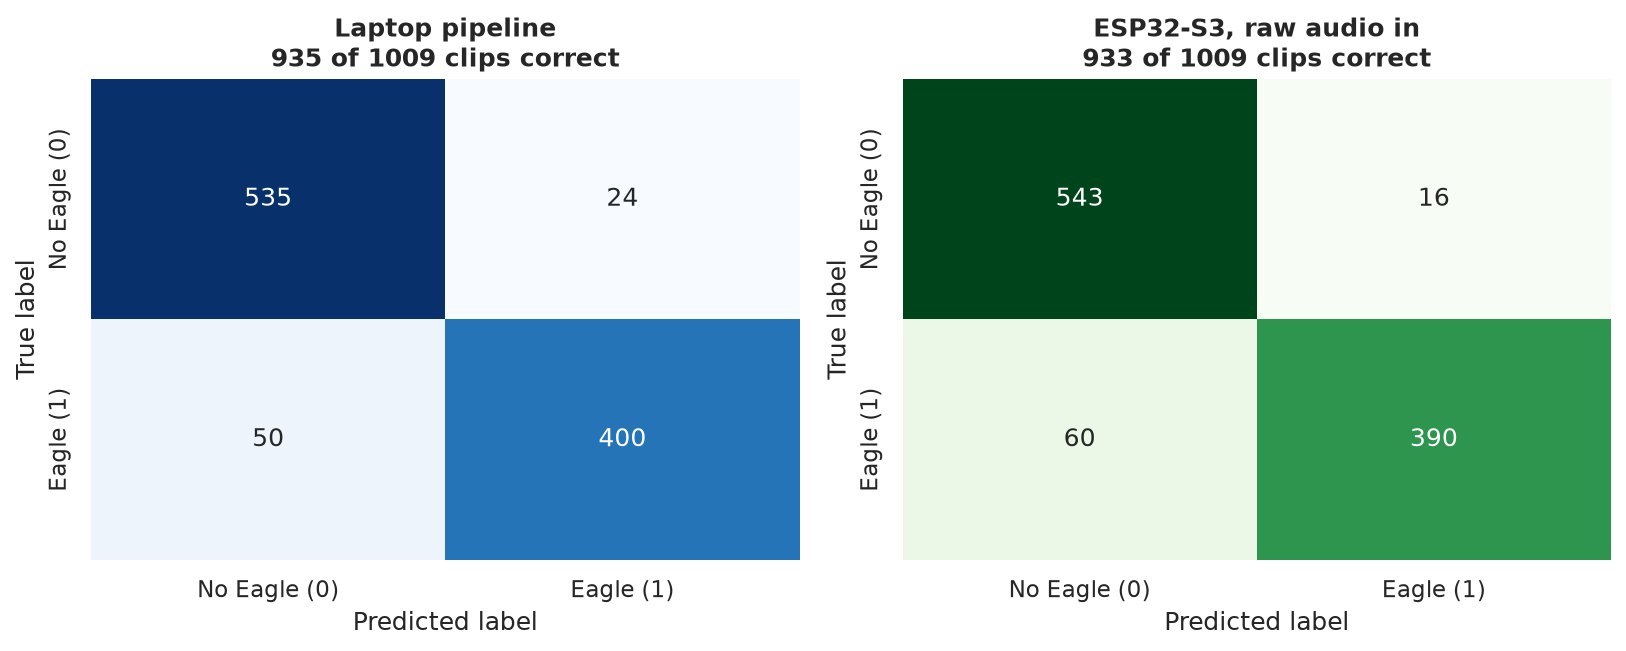

In [8]:
# Compare decisions and outputs on the clips the board answered
df_ok = df_eval[df_eval["esp_prob"].notna()].copy()
df_ok["esp_pred"] = df_ok["esp_pred"].astype(int)

agree = int((df_ok["esp_pred"] == df_ok["laptop_pred"]).sum())
raw_diff = (df_ok["esp_raw_int8"] - df_ok["laptop_raw_int8"]).abs()
print("=" * 70)
print("RAW AUDIO ON THE BOARD vs. LAPTOP PIPELINE")
print("=" * 70)
print(f"Same decision:                 {agree} of {len(df_ok)} clips")
print(f"Identical raw INT8 output:     {int((raw_diff == 0).sum())} of {len(df_ok)} clips")
print(f"Largest raw output difference: {int(raw_diff.max())} (out of 255)")
print(f"Mean probability difference:   {(df_ok['esp_prob'] - df_ok['laptop_prob']).abs().mean():.4f}")
print("=" * 70)

group_rows = []
for group in GROUPS:
    g = df_ok[df_ok["group"] == group]
    group_rows.append({
        "Group": group,
        "Clips": len(g),
        "Laptop correct": int((g["laptop_pred"] == g["label"]).sum()),
        "Board correct": int((g["esp_pred"] == g["label"]).sum()),
        "Same decision": int((g["esp_pred"] == g["laptop_pred"]).sum()),
        "Board mean probability": round(g["esp_prob"].mean(), 3),
    })
df_groups = pd.DataFrame(group_rows)
display(df_groups)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, col, title, cmap in [(axes[0], "laptop_pred", "Laptop pipeline", "Blues"), (axes[1], "esp_pred", "ESP32-S3, raw audio in", "Greens")]:
    cm = confusion_matrix(df_ok["label"], df_ok[col], labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap=cmap, cbar=False, ax=ax,
                xticklabels=["No Eagle (0)", "Eagle (1)"], yticklabels=["No Eagle (0)", "Eagle (1)"])
    ax.set_title(f"{title}\n{(df_ok[col] == df_ok['label']).sum()} of {len(df_ok)} clips correct", fontweight="bold")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
plt.tight_layout()
cm_fig_path = FIGURES_DIR / "end-to-end-confusion-matrices.png"
fig.savefig(cm_fig_path, dpi=300, bbox_inches="tight")
print(f"Saved confusion matrices to: {cm_fig_path}")
plt.show()


## 9. On-Board Timing


,Stage,Mean (ms),Min (ms),Max (ms),Std (ms)
0,Feature extraction,242.23,240.86,242.27,0.11
1,Inference,171.78,171.77,171.83,0.01
2,Total,414.01,412.67,414.06,0.11


Real-time factor: 0.138 (processing time divided by the 3.0 s clip length)
Saved timing figure to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/edge-end-to-end-benchmark/outputs/figures/end-to-end-timing.png


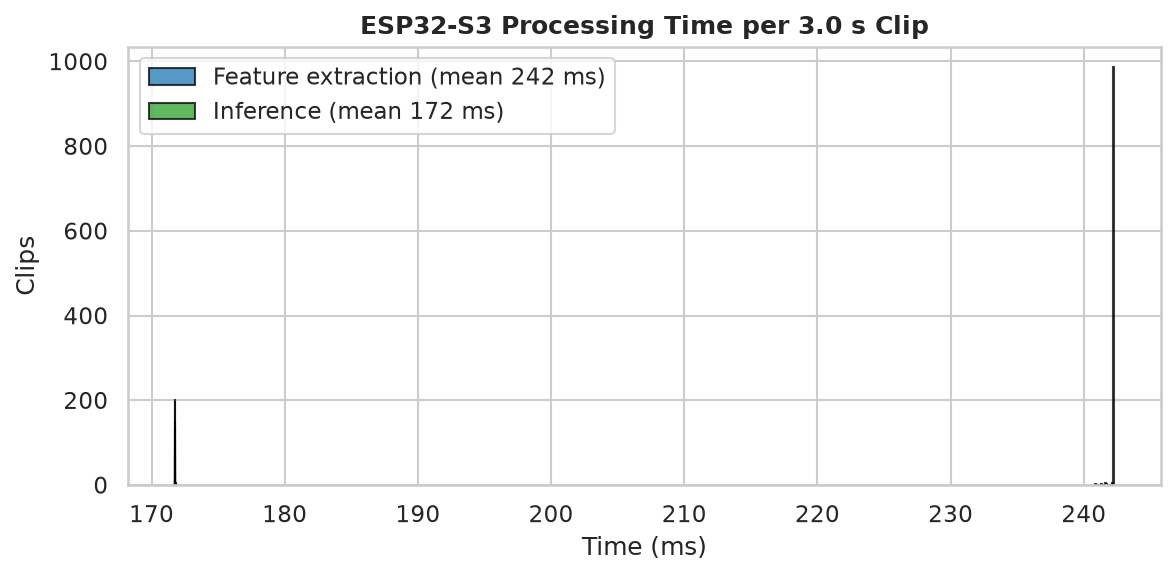

In [9]:
# Time spent on the chip per clip, split into feature extraction and inference
timing_rows = []
for name, col in [("Feature extraction", "esp_feature_ms"), ("Inference", "esp_inference_ms"), ("Total", "esp_total_ms")]:
    timing_rows.append({"Stage": name, "Mean (ms)": df_ok[col].mean(), "Min (ms)": df_ok[col].min(),
                        "Max (ms)": df_ok[col].max(), "Std (ms)": df_ok[col].std()})
df_timing = pd.DataFrame(timing_rows).round(2)
display(df_timing)

total_mean_ms = df_ok["esp_total_ms"].mean()
print(f"Real-time factor: {total_mean_ms / 3000.0:.3f} (processing time divided by the 3.0 s clip length)")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df_ok["esp_feature_ms"], bins=20, alpha=0.75, label=f"Feature extraction (mean {df_ok['esp_feature_ms'].mean():.0f} ms)", color="#1f77b4", edgecolor="black")
ax.hist(df_ok["esp_inference_ms"], bins=20, alpha=0.75, label=f"Inference (mean {df_ok['esp_inference_ms'].mean():.0f} ms)", color="#2ca02c", edgecolor="black")
ax.set_title("ESP32-S3 Processing Time per 3.0 s Clip", fontweight="bold")
ax.set_xlabel("Time (ms)")
ax.set_ylabel("Clips")
ax.legend()
plt.tight_layout()
timing_fig_path = FIGURES_DIR / "end-to-end-timing.png"
fig.savefig(timing_fig_path, dpi=300, bbox_inches="tight")
print(f"Saved timing figure to: {timing_fig_path}")
plt.show()


## 10. Detection Metrics of the Laptop Pipeline and the Board

,Laptop pipeline,"ESP32-S3, raw audio in"
Accuracy,0.9267,0.9247
Precision,0.9434,0.9606
Recall,0.8889,0.8667
F1-Score,0.9153,0.9112
Specificity,0.9571,0.9714
ROC-AUC,0.9756,0.9752
TN,535.0000,543.0000
FP,24.0000,16.0000
FN,50.0000,60.0000
TP,400.0000,390.0000


Saved metrics comparison figure to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/edge-end-to-end-benchmark/outputs/figures/end-to-end-metrics-comparison.png


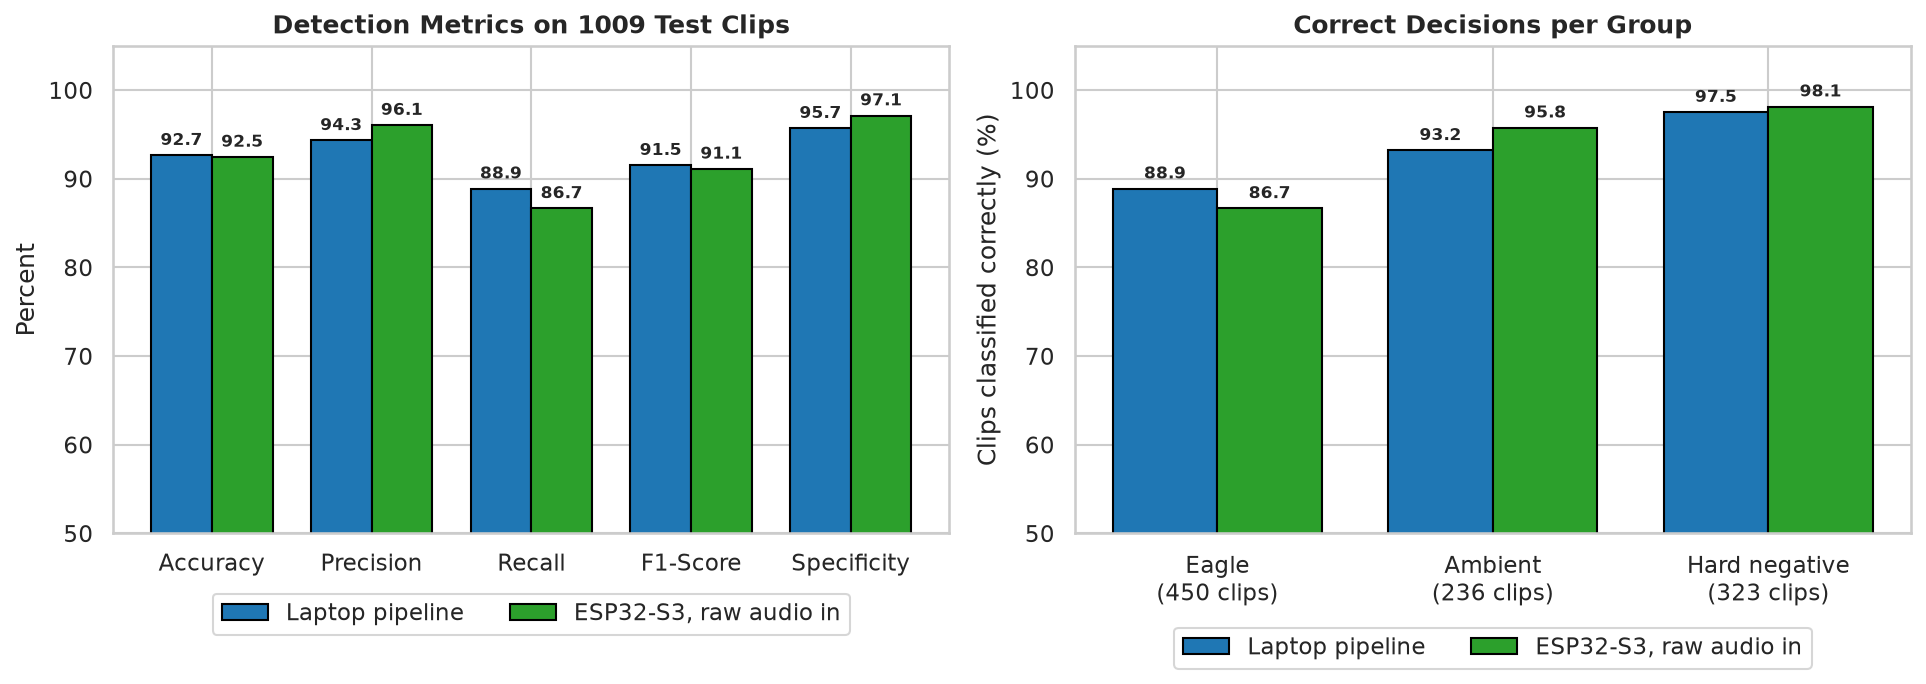

In [10]:
# Detection metrics of both pipelines on the clips the board answered, at a decision threshold of 0.50
def detection_metrics(y_true, y_pred, y_prob):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    return {
        "Accuracy": (tp + tn) / (tp + tn + fp + fn),
        "Precision": precision,
        "Recall": recall,
        "F1-Score": 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0,
        "Specificity": tn / (tn + fp) if (tn + fp) else 0.0,
        "ROC-AUC": roc_auc_score(y_true, y_prob) if len(np.unique(y_true)) > 1 else np.nan,
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
    }

PIPELINES = [("Laptop pipeline", "laptop_pred", "laptop_prob", "#1f77b4"), ("ESP32-S3, raw audio in", "esp_pred", "esp_prob", "#2ca02c")]
pipeline_metrics = {name: detection_metrics(df_ok["label"], df_ok[pred_col], df_ok[prob_col]) for name, pred_col, prob_col, _ in PIPELINES}
df_metrics = pd.DataFrame(pipeline_metrics)
display(df_metrics.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# Left: the five rate metrics side by side
rate_names = ["Accuracy", "Precision", "Recall", "F1-Score", "Specificity"]
x = np.arange(len(rate_names))
width = 0.38
for offset, (name, _, _, color) in zip([-width / 2, width / 2], PIPELINES):
    values = [pipeline_metrics[name][m] * 100 for m in rate_names]
    bars = axes[0].bar(x + offset, values, width, label=name, color=color, edgecolor="black")
    for bar, value in zip(bars, values):
        axes[0].annotate(f"{value:.1f}", (bar.get_x() + bar.get_width() / 2, value), xytext=(0, 3), textcoords="offset points",
                         ha="center", va="bottom", fontsize=8, fontweight="bold")
axes[0].set_xticks(x)
axes[0].set_xticklabels(rate_names)
axes[0].set_ylim(50, 105)
axes[0].set_ylabel("Percent")
axes[0].set_title(f"Detection Metrics on {len(df_ok)} Test Clips", fontweight="bold")
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.10), ncol=2, frameon=True)

# Right: share of clips classified correctly in each group
x = np.arange(len(GROUPS))
for offset, (name, pred_col, _, color) in zip([-width / 2, width / 2], PIPELINES):
    values = [(df_ok[df_ok["group"] == g][pred_col] == df_ok[df_ok["group"] == g]["label"]).mean() * 100 for g in GROUPS]
    bars = axes[1].bar(x + offset, values, width, label=name, color=color, edgecolor="black")
    for bar, value in zip(bars, values):
        axes[1].annotate(f"{value:.1f}", (bar.get_x() + bar.get_width() / 2, value), xytext=(0, 3), textcoords="offset points",
                         ha="center", va="bottom", fontsize=8, fontweight="bold")
axes[1].set_xticks(x)
axes[1].set_xticklabels([f"{g}\n({(df_ok['group'] == g).sum()} clips)" for g in GROUPS])
axes[1].set_ylim(50, 105)
axes[1].set_ylabel("Clips classified correctly (%)")
axes[1].set_title("Correct Decisions per Group", fontweight="bold")
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2, frameon=True)

plt.tight_layout()
metrics_fig_path = FIGURES_DIR / "end-to-end-metrics-comparison.png"
fig.savefig(metrics_fig_path, dpi=300, bbox_inches="tight")
print(f"Saved metrics comparison figure to: {metrics_fig_path}")
plt.show()


## 11. Probability Agreement Between the Board and the Laptop

Saved probability agreement figure to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/edge-end-to-end-benchmark/outputs/figures/end-to-end-probability-agreement.png


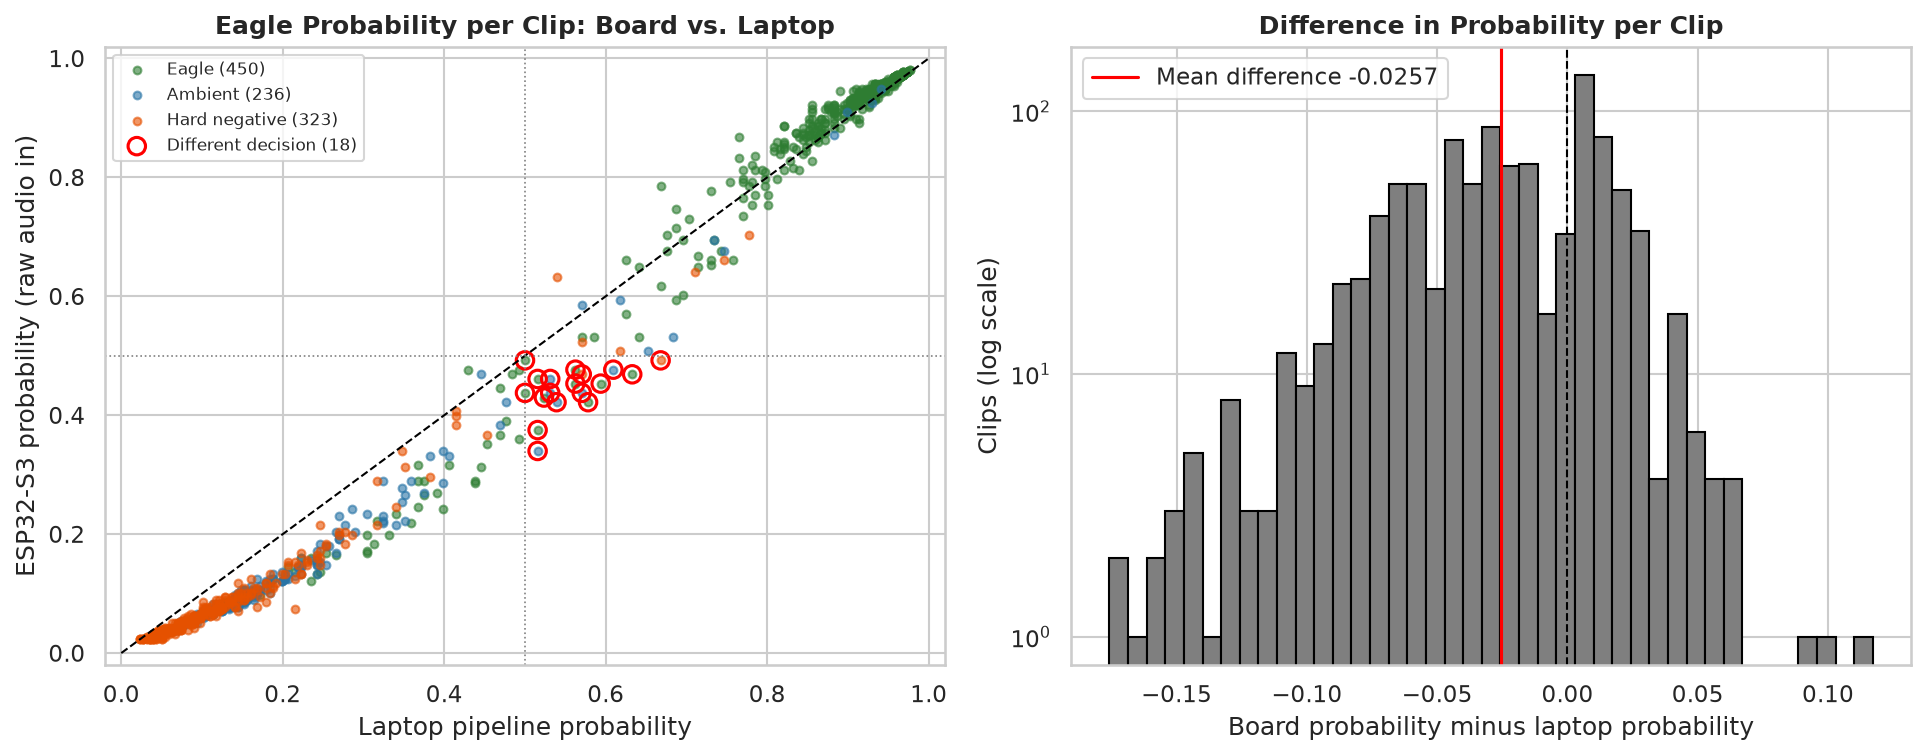

Clips with a different decision: 18 of 1009
  Laptop says eagle, board says no eagle: 18
  Laptop says no eagle, board says eagle: 0


In [11]:
# Compare the probability the board returns with the laptop's probability for the same clip
group_colors = {"Eagle": "#2e7d32", "Ambient": "#2874a6", "Hard negative": "#e65100"}
disagree = df_ok["esp_pred"] != df_ok["laptop_pred"]
prob_diff = df_ok["esp_prob"] - df_ok["laptop_prob"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))

# Left: one point per clip; points on the diagonal have the same probability on both sides
for group in GROUPS:
    g = df_ok[df_ok["group"] == group]
    axes[0].scatter(g["laptop_prob"], g["esp_prob"], s=14, alpha=0.6, color=group_colors[group], label=f"{group} ({len(g)})")
axes[0].scatter(df_ok[disagree]["laptop_prob"], df_ok[disagree]["esp_prob"], s=70, facecolors="none", edgecolors="red", linewidths=1.5,
                label=f"Different decision ({int(disagree.sum())})")
axes[0].plot([0, 1], [0, 1], color="black", lw=1, linestyle="--")
axes[0].axhline(0.5, color="gray", lw=0.8, linestyle=":")
axes[0].axvline(0.5, color="gray", lw=0.8, linestyle=":")
axes[0].set_xlim(-0.02, 1.02)
axes[0].set_ylim(-0.02, 1.02)
axes[0].set_xlabel("Laptop pipeline probability")
axes[0].set_ylabel("ESP32-S3 probability (raw audio in)")
axes[0].set_title("Eagle Probability per Clip: Board vs. Laptop", fontweight="bold")
axes[0].legend(loc="upper left", frameon=True, fontsize=8)

# Right: how far the board's probability is from the laptop's
axes[1].hist(prob_diff, bins=41, color="#7f7f7f", edgecolor="black")
axes[1].axvline(0, color="black", lw=1, linestyle="--")
axes[1].axvline(prob_diff.mean(), color="red", lw=1.5, label=f"Mean difference {prob_diff.mean():+.4f}")
axes[1].set_yscale("log")
axes[1].set_xlabel("Board probability minus laptop probability")
axes[1].set_ylabel("Clips (log scale)")
axes[1].set_title("Difference in Probability per Clip", fontweight="bold")
axes[1].legend(frameon=True)

plt.tight_layout()
prob_fig_path = FIGURES_DIR / "end-to-end-probability-agreement.png"
fig.savefig(prob_fig_path, dpi=300, bbox_inches="tight")
print(f"Saved probability agreement figure to: {prob_fig_path}")
plt.show()

print(f"Clips with a different decision: {int(disagree.sum())} of {len(df_ok)}")
print(f"  Laptop says eagle, board says no eagle: {int(((df_ok['laptop_pred'] == 1) & (df_ok['esp_pred'] == 0)).sum())}")
print(f"  Laptop says no eagle, board says eagle: {int(((df_ok['laptop_pred'] == 0) & (df_ok['esp_pred'] == 1)).sum())}")


## 12. On-Board Time Budget per Clip

Saved time budget figure to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/edge-end-to-end-benchmark/outputs/figures/end-to-end-time-budget.png


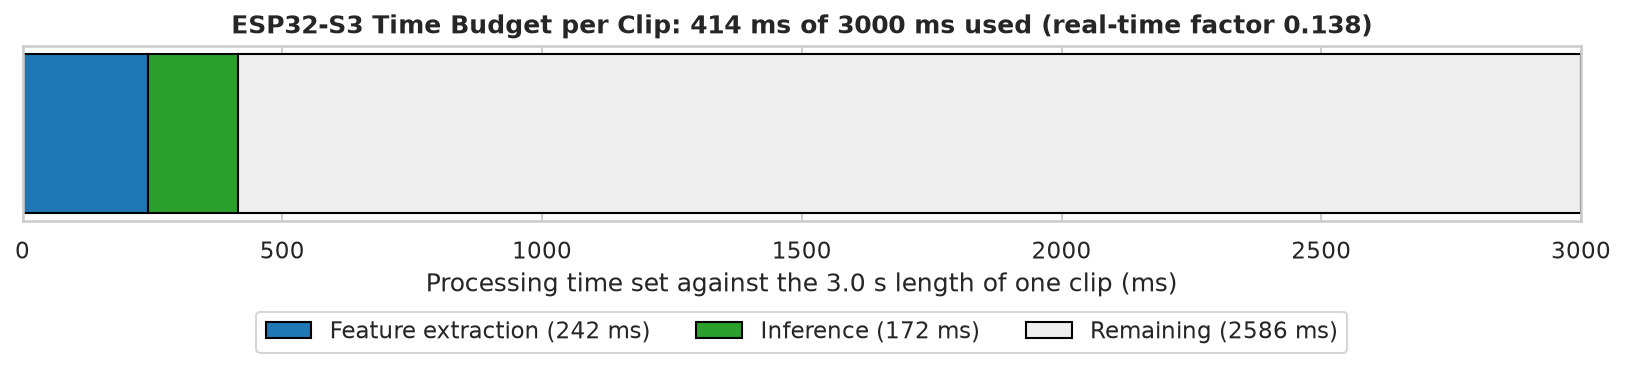

In [12]:
# Mean on-board processing time per clip, set against the 3.0-second length of the clip
feature_mean_ms = df_ok["esp_feature_ms"].mean()
inference_mean_ms = df_ok["esp_inference_ms"].mean()
clip_ms = N_SAMPLES / SR * 1000.0

fig, ax = plt.subplots(figsize=(11, 3.2))
ax.barh(0, feature_mean_ms, color="#1f77b4", edgecolor="black", label=f"Feature extraction ({feature_mean_ms:.0f} ms)")
ax.barh(0, inference_mean_ms, left=feature_mean_ms, color="#2ca02c", edgecolor="black", label=f"Inference ({inference_mean_ms:.0f} ms)")
ax.barh(0, clip_ms - total_mean_ms, left=total_mean_ms, color="#eeeeee", edgecolor="black",
        label=f"Remaining ({clip_ms - total_mean_ms:.0f} ms)")
ax.set_xlim(0, clip_ms)
ax.set_yticks([])
ax.set_xlabel("Processing time set against the 3.0 s length of one clip (ms)")
ax.set_title(f"ESP32-S3 Time Budget per Clip: {total_mean_ms:.0f} ms of {clip_ms:.0f} ms used (real-time factor {total_mean_ms / clip_ms:.3f})", fontweight="bold")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.45), ncol=3, frameon=True)
plt.tight_layout()
budget_fig_path = FIGURES_DIR / "end-to-end-time-budget.png"
fig.savefig(budget_fig_path, dpi=300, bbox_inches="tight")
print(f"Saved time budget figure to: {budget_fig_path}")
plt.show()


## 13. Export Results

In [13]:
# Save per-clip results and the summary tables
suffix = f"{len(df_eval)}-clips"
results_path = OUTPUTS_DIR / f"end-to-end-results-{suffix}.csv"
export_cols = ["clip_idx", "group", "audio_file", "species", "site", "source_audio", "label",
               "laptop_raw_int8", "laptop_prob", "laptop_pred",
               "esp_raw_int8", "esp_prob", "esp_pred", "esp_feature_ms", "esp_inference_ms", "esp_total_ms", "board_model"]
# The board model is recorded with the results, so section 5 can tell whether saved results belong to the current model
df_eval["board_model"] = BOARD_MODEL_ID
df_eval[export_cols].to_csv(results_path, index=False)
print(f"Saved per-clip results to: {results_path}")
if board_info:
    board_info_path.write_text(json.dumps(board_info, indent=2))
    print(f"Saved board handshake information to: {board_info_path}")

groups_path = OUTPUTS_DIR / f"end-to-end-groups-{suffix}.csv"
df_groups.to_csv(groups_path, index=False)
timing_path = OUTPUTS_DIR / f"end-to-end-timing-{suffix}.csv"
df_timing.to_csv(timing_path, index=False)
if len(df_match):
    match_path = OUTPUTS_DIR / f"feature-matching-{suffix}.csv"
    df_match.to_csv(match_path, index=False)
    print(f"Saved feature matching table to: {match_path}")
print(f"Saved group summary to: {groups_path}")
print(f"Saved timing summary to: {timing_path}")


# Text files: one per pipeline with its detection statistics, and one per summary table
STATISTICS_DIR = OUTPUTS_DIR / "statistics"
STATISTICS_DIR.mkdir(parents=True, exist_ok=True)

for name, pred_col, prob_col, _ in PIPELINES:
    m = pipeline_metrics[name]
    lines = [
        "=" * 65,
        f"EVALUATION RESULTS: {name} ({len(df_ok)} test clips)",
        "=" * 65,
        f"Accuracy:    {m['Accuracy']:.4f} ({m['Accuracy'] * 100:.2f}%)",
        f"Precision:   {m['Precision']:.4f} ({m['Precision'] * 100:.2f}%)",
        f"Recall:      {m['Recall']:.4f} ({m['Recall'] * 100:.2f}%)",
        f"F1-Score:    {m['F1-Score']:.4f} ({m['F1-Score'] * 100:.2f}%)",
        f"Specificity: {m['Specificity']:.4f} ({m['Specificity'] * 100:.2f}%)",
        f"ROC-AUC:     {m['ROC-AUC']:.4f}",
        f"Confusion:   TN {m['TN']} | FP {m['FP']} | FN {m['FN']} | TP {m['TP']}",
        "=" * 65,
        classification_report(df_ok["label"], df_ok[pred_col], labels=[0, 1], target_names=["No Eagle (0)", "Eagle (1)"], zero_division=0),
    ]
    file_stem = "laptop-pipeline" if pred_col == "laptop_pred" else "esp32-s3-raw-audio"
    stats_path = STATISTICS_DIR / f"{file_stem}-statistics-{suffix}.txt"
    stats_path.write_text("\n".join(lines) + "\n")
    print(f"Saved statistics to: {stats_path}")

agreement_path = STATISTICS_DIR / f"end-to-end-agreement-{suffix}.txt"
agreement_path.write_text("\n".join([
    "=" * 70,
    "RAW AUDIO ON THE BOARD vs. LAPTOP PIPELINE",
    "=" * 70,
    f"Clips answered by the board:   {len(df_ok)} of {len(df_eval)}",
    f"Same decision:                 {agree} of {len(df_ok)} clips ({agree / len(df_ok) * 100:.2f}%)",
    f"Identical raw INT8 output:     {int((raw_diff == 0).sum())} of {len(df_ok)} clips",
    f"Largest raw output difference: {int(raw_diff.max())} (out of 255)",
    f"Mean probability difference:   {(df_ok['esp_prob'] - df_ok['laptop_prob']).abs().mean():.4f}",
    f"Laptop eagle, board no eagle:  {int(((df_ok['laptop_pred'] == 1) & (df_ok['esp_pred'] == 0)).sum())}",
    f"Laptop no eagle, board eagle:  {int(((df_ok['laptop_pred'] == 0) & (df_ok['esp_pred'] == 1)).sum())}",
    "=" * 70,
    df_groups.to_string(index=False),
    "",
]))
print(f"Saved agreement summary to: {agreement_path}")

timing_txt_path = STATISTICS_DIR / f"end-to-end-timing-{suffix}.txt"
timing_txt_path.write_text("\n".join([
    "=" * 70,
    f"ON-BOARD PROCESSING TIME PER 3.0 s CLIP ({len(df_ok)} clips)",
    "=" * 70,
    df_timing.to_string(index=False),
    "",
    f"Real-time factor: {total_mean_ms / 3000.0:.3f} (total processing time divided by the 3.0 s clip length)",
    (f"Tensor arena:     {board_info.get('arena_kb')} KB reserved, {int(board_info.get('arena_used', 0)) / 1024:.1f} KB used, "
     f"{'internal RAM' if board_info.get('arena_internal') == '1' else 'external PSRAM'}") if board_info else "Tensor arena:     not recorded",
    "",
]))
print(f"Saved timing summary to: {timing_txt_path}")

if len(df_match):
    match_txt_path = STATISTICS_DIR / f"feature-matching-{suffix}.txt"
    match_txt_path.write_text("\n".join([
        "=" * 70,
        "ON-BOARD SPECTROGRAM vs. LAPTOP SPECTROGRAM (INT8 values)",
        "=" * 70,
        df_match.round(3).to_string(index=False),
        "",
        f"Identical INT8 values overall: {df_match['identical values (%)'].mean():.3f}%",
        f"Largest difference:            {df_match['max difference'].max()}",
        "",
    ]))
    print(f"Saved feature matching summary to: {match_txt_path}")


Saved per-clip results to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/edge-end-to-end-benchmark/outputs/end-to-end-results-1009-clips.csv
Saved board handshake information to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/edge-end-to-end-benchmark/outputs/end-to-end-board-info-1009-clips.json
Saved feature matching table to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/edge-end-to-end-benchmark/outputs/feature-matching-1009-clips.csv
Saved group summary to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/edge-end-to-end-benchmark/outputs/end-to-end-groups-1009-clips.csv
Saved timing summary to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/edge-end-to-end-benchmark/outputs/end-to-end-timing-1009-clips.csv
Saved statistics to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/edge-end-to-end-benchmark/outputs/statisti